# Mandatory assignment 3

**GitHub repository:** *https://github.com/Praapthi06/TECH2-H26-assignment3.git*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [5]:
#Implementation for part 1

#Make sure to use relative paths!

file = 'SCF_10pct.csv'
import pandas as pd

df = pd.read_csv(file)
df

,id,year,age,educ,stocks,equity
0,0,1989,35,2.0,0.0,0.0
1,1,1989,33,2.0,0.0,0.0
2,2,1989,62,1.0,0.0,0.0
3,3,1989,23,2.0,0.0,0.0
4,4,1989,70,1.0,0.0,0.0
...,...,...,...,...,...,...
5803,5803,2022,21,2.0,0.0,0.0
5804,5804,2022,33,3.0,0.0,0.0
5805,5805,2022,81,2.0,100000.0,100000.0
5806,5806,2022,58,3.0,40000.0,1212000.0


In [6]:
df.info(show_counts = True)

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


In [7]:
#Implementation for part 2

variables = ["id", "year", "age", "educ", "stocks", "equity"]

for var in variables:
    initial_rows = len(df)
    df = df.dropna(subset=[var])
    remaining_rows = len(df)
    rows_dropped = initial_rows - remaining_rows 

    print(f'{var}: dropped {rows_dropped}, remaining {remaining_rows}')


id: dropped 0, remaining 5808
year: dropped 0, remaining 5808
age: dropped 0, remaining 5808
educ: dropped 16, remaining 5792
stocks: dropped 18, remaining 5774
equity: dropped 16, remaining 5758


In [8]:
#Implementation for part 3

initial_rows = len(df)

mask = (df['age'] >=25) & (df['age'] <=89)
df = df.loc[mask]

remaining_rows = len(df)
rows_dropped = initial_rows-remaining_rows 

print(f'Observations dropped: {rows_dropped}, observations remaining: {remaining_rows}')

Observations dropped: 326, observations remaining: 5432


In [9]:
#Implementation for part 4
#Create two 0/1 indicator columns 

df['direct'] = (df['stocks']>0).astype(int)
df['direct']

0       0
1       0
2       0
4       0
5       0
       ..
5802    0
5804    0
5805    1
5806    1
5807    0
Name: direct, Length: 5432, dtype: int64

In [10]:
df['overall'] = (df['equity']>0).astype(int)
df['overall']

0       0
1       0
2       0
4       0
5       0
       ..
5802    0
5804    0
5805    1
5806    1
5807    1
Name: overall, Length: 5432, dtype: int64

In [11]:
df['direct'].value_counts()

direct
0    4511
1     921
Name: count, dtype: int64

In [12]:
df['overall'].value_counts()

overall
0    2748
1    2684
Name: count, dtype: int64

In [13]:
mask_check = (df['direct']==1) & (df['overall']==0).sum()
print(mask_check.sum())
df.loc[mask_check]
#No households have direct stock holdings without positive equity, indicators are consistent

0


,id,year,age,educ,stocks,equity,direct,overall


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [14]:
#Implementation for part 1 and 2
def participation_rate(indicator):
    count_ones = 0
    for value in indicator:
        if value == 1:
            count_ones += 1
    p_rate = count_ones/len(indicator)*100
    return p_rate

direct_loop = participation_rate(df['direct'])
overall_loop = participation_rate(df['overall'])
print(f'Direct participation rate is: {direct_loop:.2f}%')
print(f'Overall participation rate is: {overall_loop:.2f}%')

Direct participation rate is: 16.96%
Overall participation rate is: 49.41%


In [15]:
#Implementation for part 3
import pandas as pd
direct_mean = df['direct'].mean()*100
print(f'Pandas mean method gives direct participation rate {direct_mean:.2f}%')

overall_mean = df['overall'].mean()*100
print(f'Pandas mean method gives overall participation rate: {overall_mean:.2f}%')

Pandas mean method gives direct participation rate 16.96%
Pandas mean method gives overall participation rate: 49.41%


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [29]:
#education levels are given as a float, convert to int and then into list

educ_category = [1, 2, 3, 4]
direct_rates = []
overall_rates = []

for e in educ_category:
    group = df.loc[df['educ']==e]  #makes a new dataframe group with the rows that satisfy the loc condition
    direct = participation_rate(group['direct'])
    direct_rates.append(direct)
    #Alternative: print(f'Education level {e}: direct participation: {direct_rates[-1]}')
    overall = participation_rate(group['overall'])
    overall_rates.append(overall)
    print(f'Education category {e}, direct participation: {direct:.1f}%, overall participation: {overall:.1f}%')


Education category 1, direct participation: 4.4%, overall participation: 17.3%
Education category 2, direct participation: 11.4%, overall participation: 39.9%
Education category 3, direct participation: 13.5%, overall participation: 48.3%
Education category 4, direct participation: 30.5%, overall participation: 73.5%


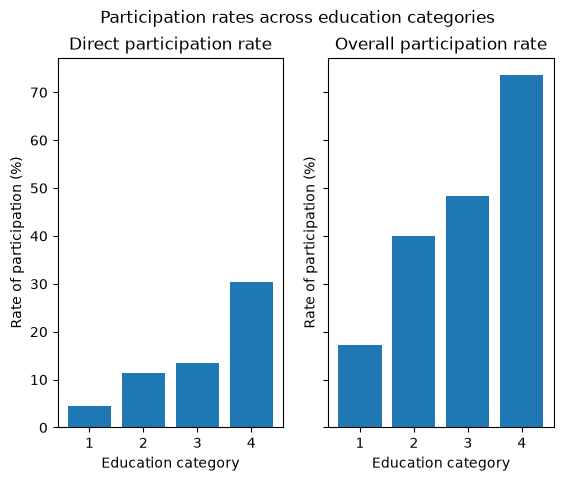

In [39]:
#Plotting
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1,2, sharey=True)
fig.suptitle("Participation rates across education categories")
x = educ_category

ax1.bar(x,direct_rates, width=0.8)
ax1.set_title("Direct participation rate")
ax1.set_xlabel("Education category")
ax1.set_ylabel("Rate of participation (%)")


ax2.bar(x,overall_rates, width=0.8)
ax2.set_title("Overall participation rate")
ax2.set_xlabel("Education category")
ax2.set_ylabel("Rate of participation (%)")
plt.show()

According to the figure above, the trend is that participation rates increase across the education categories with the highest level of participation at category 4. It can be seen that the overall participation rate is greater than the direct participation rate.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [52]:
years = df['year'].sort_values().unique()

direct_rates_year = []
overall_rates_year = []

for year in years:
    group_year = df.loc[df['year']==year]  #makes a new dataframe group with the rows that satisfy the loc condition
    direct_year = participation_rate(group_year['direct'])
    direct_rates_year.append(direct_year)
    overall_year = participation_rate(group_year['overall'])
    overall_rates_year.append(overall_year)
    print(f'In year {year}, direct participation: {direct_year:.1f}%, overall participation: {overall_year:.1f}%')


In year 1989, direct participation: 15.6%, overall participation: 31.6%
In year 1992, direct participation: 18.3%, overall participation: 40.1%
In year 1995, direct participation: 15.7%, overall participation: 45.9%
In year 1998, direct participation: 19.9%, overall participation: 51.2%
In year 2001, direct participation: 21.8%, overall participation: 57.0%
In year 2004, direct participation: 18.9%, overall participation: 54.7%
In year 2007, direct participation: 17.3%, overall participation: 56.5%
In year 2010, direct participation: 17.4%, overall participation: 50.3%
In year 2013, direct participation: 14.8%, overall participation: 49.9%
In year 2016, direct participation: 12.3%, overall participation: 52.0%
In year 2019, direct participation: 12.4%, overall participation: 49.8%
In year 2022, direct participation: 19.2%, overall participation: 54.3%


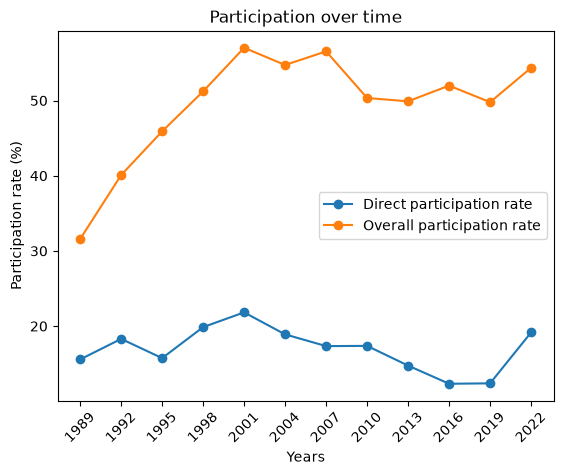

In [63]:
xvalues = years
yvalues1 = direct_rates
yvalues2 = overall_rates

plt.plot(xvalues, yvalues1, label="Direct participation rate", marker='o')
plt.plot(xvalues, yvalues2, label = "Overall participation rate", marker='o')
plt.title("Participation over time")
plt.xlabel("Years")
plt.ylabel("Participation rate (%)")
plt.legend()
plt.xticks(years, rotation=45)
plt.show()

In [ ]:
first_direct = direct_rates_year[0]
last_direct = direct_rates_year[-1]
change_direct = last_direct-first_direct
print(f'Change in direct participation rates from 1989 to 2022 is {change_direct:.1f} pp')


first_overall = overall_rates_year[0]
last_overall = overall_rates_year[-1]
change_overall = last_overall-first_overall
print(f'Change in overall participation rates from 1989 to 2022 is {change_overall:.1f} pp')



Change in direct participation rates from 1989 to 2022 is 3.6 pp
Change in overall participation rates from 1989 to 2022 is 22.8 pp


***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used AI as a tool to guide me through the tasks and to fix errors in my code. I did not copy paste any code, I simply explained my thought process, gave it snippets of my code and got feedback on where the code was wrong and what I could improve on for it to run well.